## 1. Data Loading and Inspection

Loading the matches dataset (`matches_1930_2022.csv`), the October 2022 FIFA ranking snapshot (`fifa_ranking_2022-10-06.csv`, used only for initial name checks), and the historical FIFA ranking dataset (`fifa_ranking-2024-06-20.csv`, every ranking release since December 1992), and inspecting their shape, columns, and data types before cleaning.

In [1]:
#Import statements
import pandas as pd
import numpy as np

In [2]:
#Load data:
matches = pd.read_csv("matches_1930_2022.csv")
ranking = pd.read_csv("fifa_ranking_2022-10-06.csv")

In [3]:
# Load the historical FIFA ranking file (every ranking release since 1992)
hist_rank = pd.read_csv("fifa_ranking-2024-06-20.csv")
hist_rank["rank_date"] = pd.to_datetime(hist_rank["rank_date"])
print(hist_rank.shape)
print(hist_rank["rank_date"].min(), "to", hist_rank["rank_date"].max())
hist_rank.head()

(67472, 8)
1992-12-31 00:00:00 to 2024-06-20 00:00:00


,rank,country_full,country_abrv,total_points,previous_points,rank_change,confederation,rank_date
0,140.0,Brunei Darussalam,BRU,2.0,0.0,140,AFC,1992-12-31
1,33.0,Portugal,POR,38.0,0.0,33,UEFA,1992-12-31
2,32.0,Zambia,ZAM,38.0,0.0,32,CAF,1992-12-31
3,31.0,Greece,GRE,38.0,0.0,31,UEFA,1992-12-31
4,30.0,Algeria,ALG,39.0,0.0,30,CAF,1992-12-31


In [4]:
print("MATCHES")
print(matches.shape)
print(matches.columns.tolist())
matches.head()

MATCHES
(964, 44)
['home_team', 'away_team', 'home_score', 'home_xg', 'home_penalty', 'away_score', 'away_xg', 'away_penalty', 'home_manager', 'home_captain', 'away_manager', 'away_captain', 'Attendance', 'Venue', 'Officials', 'Round', 'Date', 'Score', 'Referee', 'Notes', 'Host', 'Year', 'home_goal', 'away_goal', 'home_goal_long', 'away_goal_long', 'home_own_goal', 'away_own_goal', 'home_penalty_goal', 'away_penalty_goal', 'home_penalty_miss_long', 'away_penalty_miss_long', 'home_penalty_shootout_goal_long', 'away_penalty_shootout_goal_long', 'home_penalty_shootout_miss_long', 'away_penalty_shootout_miss_long', 'home_red_card', 'away_red_card', 'home_yellow_red_card', 'away_yellow_red_card', 'home_yellow_card_long', 'away_yellow_card_long', 'home_substitute_in_long', 'away_substitute_in_long']


,home_team,away_team,home_score,home_xg,home_penalty,away_score,away_xg,away_penalty,home_manager,home_captain,...,home_penalty_shootout_miss_long,away_penalty_shootout_miss_long,home_red_card,away_red_card,home_yellow_red_card,away_yellow_red_card,home_yellow_card_long,away_yellow_card_long,home_substitute_in_long,away_substitute_in_long
0,Argentina,France,3,3.3,4.0,3,2.2,2.0,Lionel Scaloni,Lionel Messi,...,NaN,"['3|1:1|Kingsley Coman', '5|2:1|Aurélien Tchou...",NaN,NaN,NaN,NaN,"['45+7&rsquor;|2:0|Enzo Fernández', '90+8&rsqu...","['55&rsquor;|2:0|Adrien Rabiot', '87&rsquor;|2...",['64&rsquor;|2:0|Marcos Acuña|for Ángel Di Mar...,['41&rsquor;|2:0|Randal Kolo Muani|for Ousmane...
1,Croatia,Morocco,2,0.7,NaN,1,1.2,NaN,Zlatko Dalić,Luka Modrić,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"['69&rsquor;|2:1|Azzedine Ounahi', '84&rsquor;...",['61&rsquor;|2:1|Nikola Vlašić|for Andrej Kram...,['46&rsquor;|2:1|Ilias Chair|for Abdelhamid Sa...
2,France,Morocco,2,2.0,NaN,0,0.9,NaN,Didier Deschamps,Hugo Lloris,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,['27&rsquor;|1:0|Sofiane Boufal'],['65&rsquor;|1:0|Marcus Thuram|for Olivier Gir...,['21&rsquor;|1:0|Selim Amallah|for Romain Saïs...
3,Argentina,Croatia,3,2.3,NaN,0,0.5,NaN,Lionel Scaloni,Lionel Messi,...,NaN,NaN,NaN,NaN,NaN,NaN,"['68&rsquor;|2:0|Cristian Romero', '71&rsquor;...","['32&rsquor;|0:0|Mateo Kovačić', '32&rsquor;|0...",['62&rsquor;|2:0|Lisandro Martínez|for Leandro...,"['46&rsquor;|2:0|Mislav Oršić|for Borna Sosa',..."
4,Morocco,Portugal,1,1.4,NaN,0,0.9,NaN,Hoalid Regragui,Romain Saïss,...,NaN,NaN,NaN,NaN,Walid Cheddira · 90+3,NaN,"['70&rsquor;|1:0|Achraf Dari', '90+1&rsquor;|1...",['87&rsquor;|1:0|Vitinha'],['57&rsquor;|1:0|Achraf Dari|for Romain Saïss'...,['51&rsquor;|1:0|João Cancelo|for Raphaël Guer...


In [5]:
matches.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 964 entries, 0 to 963
Data columns (total 44 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   home_team                        964 non-null    object 
 1   away_team                        964 non-null    object 
 2   home_score                       964 non-null    int64  
 3   home_xg                          128 non-null    float64
 4   home_penalty                     35 non-null     float64
 5   away_score                       964 non-null    int64  
 6   away_xg                          128 non-null    float64
 7   away_penalty                     35 non-null     float64
 8   home_manager                     964 non-null    object 
 9   home_captain                     644 non-null    object 
 10  away_manager                     964 non-null    object 
 11  away_captain                     644 non-null    object 
 12  Attendance            

## 2. Exploratory Data Analysis

Examining the full dataset before filtering: checking for duplicate rows, missing values across all columns, and the distribution of match outcomes (win/draw/loss), since class imbalance in draws is central to this study's research gap.

In [6]:
# Check for duplicate rows and missing values across all columns
print("Duplicate rows:", matches.duplicated().sum())
print(matches.isna().sum()[matches.isna().sum() > 0])

Duplicate rows: 0
home_xg                            836
home_penalty                       929
away_xg                            836
away_penalty                       929
home_captain                       320
away_captain                       320
Officials                          255
Referee                            255
Notes                              891
home_goal                          246
away_goal                          393
home_goal_long                     246
away_goal_long                     393
home_own_goal                      925
away_own_goal                      947
home_penalty_goal                  848
away_penalty_goal                  880
home_penalty_miss_long             958
away_penalty_miss_long             955
home_penalty_shootout_goal_long    930
away_penalty_shootout_goal_long    930
home_penalty_shootout_miss_long    940
away_penalty_shootout_miss_long    934
home_red_card                      913
away_red_card                      910
home_ye

In [7]:
# Create the outcome label (win/draw/loss from home team's perspective) and check class balance
matches["outcome"] = matches.apply(lambda r: "win" if r["home_score"] > r["away_score"] else ("loss" if r["home_score"] < r["away_score"] else "draw"), axis=1)
print(matches["outcome"].value_counts())
print(matches["outcome"].value_counts(normalize=True).round(3))

outcome
win     532
loss    218
draw    214
Name: count, dtype: int64
outcome
win     0.552
loss    0.226
draw    0.222
Name: proportion, dtype: float64


In [8]:
# Check descriptive statistics for key numeric columns to spot anything unusual
matches[["home_score", "away_score", "Attendance"]].describe()

,home_score,away_score,Attendance
count,964.000000,964.000000,964.000000
mean,1.776971,1.044606,45693.374481
std,1.596676,1.071233,22704.131689
min,0.000000,0.000000,2000.000000
25%,1.000000,0.000000,31800.000000
50%,1.000000,1.000000,42725.000000
75%,3.000000,2.000000,60984.500000
max,10.000000,7.000000,173850.000000


In [9]:
# Columns actually needed for this study's features and outcome variable
relevant_cols = ["home_team", "away_team", "home_score", "away_score", "Date", "Year", "Host"]
matches[relevant_cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 964 entries, 0 to 963
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   home_team   964 non-null    object
 1   away_team   964 non-null    object
 2   home_score  964 non-null    int64 
 3   away_score  964 non-null    int64 
 4   Date        964 non-null    object
 5   Year        964 non-null    int64 
 6   Host        964 non-null    object
dtypes: int64(3), object(4)
memory usage: 52.8+ KB


The dataset contains 44 columns, but this study only requires 7: `home_team`, `away_team`, `home_score`, `away_score`, `Date`, `Year`, and `Host`. All engineered features (home advantage, FIFA ranking difference, head-to-head record, disciplinary record, rolling goals-for average) are derived from these. The dataset is trimmed to these columns for clarity; the full 44-column dataset remains available in `matches` if additional columns are needed later.

In [10]:
# Trim to only the columns needed for this study
matches = matches[["home_team", "away_team", "home_score", "away_score", "Date", "Year", "Host"]].copy()
matches.shape

(964, 7)

**Visualising class balance and tournament coverage**

Visualising the match outcome distribution and matches-per-tournament counts, to support the discussion of class imbalance and dataset coverage in the written analysis.

In [11]:
# Recreate the outcome column on the trimmed dataset
matches["outcome"] = matches.apply(lambda r: "win" if r["home_score"] > r["away_score"] else ("loss" if r["home_score"] < r["away_score"] else "draw"), axis=1)

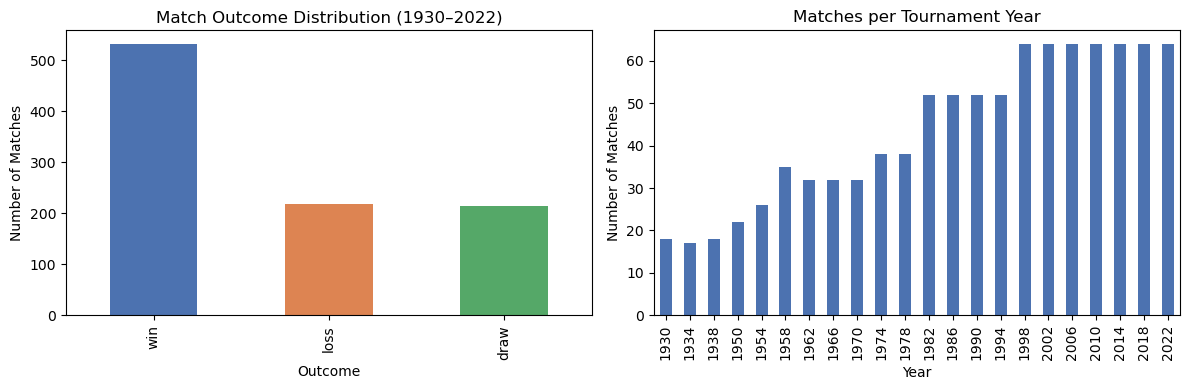

In [12]:
# Visualise outcome distribution and matches per tournament year
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
matches["outcome"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("Match Outcome Distribution (1930–2022)")
axes[0].set_xlabel("Outcome")
axes[0].set_ylabel("Number of Matches")

matches["Year"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_title("Matches per Tournament Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Number of Matches")

plt.tight_layout()
plt.show()

## 3. Filtering to 1990–2022

Restricting the matches dataset to World Cup tournaments from 1990 to 2022, per the scope defined in the research proposal. Also checking the availability of expected goals (xG) data within this range — found that xG is only present for the 2018 and 2022 tournaments (128 of 552 matches), so it will not be used as a feature. A rolling goals-for average will be used instead in Section 4, since it is available across all matches in the dataset.

In [13]:
# Filter matches to 1990–2022, per proposal scope
matches_filtered = matches[(matches["Year"] >= 1990) & (matches["Year"] <= 2022)].copy()
print(matches_filtered.shape)
print(matches_filtered["Year"].value_counts().sort_index())

(552, 8)
Year
1990    52
1994    52
1998    64
2002    64
2006    64
2010    64
2014    64
2018    64
2022    64
Name: count, dtype: int64


## 4. Chronological Sorting

Converting the `Date` column to a proper datetime type and sorting matches in chronological order, so that rolling/pre-match features can be calculated correctly using only prior matches.

In [14]:
# Convert Date column to actual datetime and sort matches chronologically
matches_filtered["Date"] = pd.to_datetime(matches_filtered["Date"])
matches_filtered = matches_filtered.sort_values("Date").reset_index(drop=True)
matches_filtered[["Date", "home_team", "away_team"]].head()

,Date,home_team,away_team
0,1990-06-08,Argentina,Cameroon
1,1990-06-09,United Arab Emirates,Colombia
2,1990-06-09,Italy,Austria
3,1990-06-09,Soviet Union,Romania
4,1990-06-10,United States,Czechoslovakia


## 5. Feature Engineering

Constructing pre-match features for each match, using only information available before kickoff to avoid data leakage. Built in order: home advantage, FIFA ranking difference, head-to-head record, disciplinary record, and rolling goals-for average (replacing xG, which was dropped in Section 2 due to missing data).

In [15]:
# Create home_advantage flag: 1 if the host nation is playing (in either home_team or away_team), else 0
matches_filtered["home_advantage"] = ((matches_filtered["home_team"] == matches_filtered["Host"]) | (matches_filtered["away_team"] == matches_filtered["Host"])).astype(int)
matches_filtered[["Date", "home_team", "away_team", "Host", "home_advantage"]].head(10)

,Date,home_team,away_team,Host,home_advantage
0,1990-06-08,Argentina,Cameroon,Italy,0
1,1990-06-09,United Arab Emirates,Colombia,Italy,0
2,1990-06-09,Italy,Austria,Italy,1
3,1990-06-09,Soviet Union,Romania,Italy,0
4,1990-06-10,United States,Czechoslovakia,Italy,0
5,1990-06-10,Brazil,Sweden,Italy,0
6,1990-06-10,West Germany,Yugoslavia,Italy,0
7,1990-06-11,England,Republic of Ireland,Italy,0
8,1990-06-11,Costa Rica,Scotland,Italy,0
9,1990-06-12,Netherlands,Egypt,Italy,0


In [16]:
# Check all of Qatar's own matches, regardless of which column they appear in
print(matches_filtered[(matches_filtered["home_team"] == "Qatar") | (matches_filtered["away_team"] == "Qatar")][["Date", "home_team", "away_team", "Host", "home_advantage"]])

          Date    home_team away_team   Host  home_advantage
488 2022-11-20        Qatar   Ecuador  Qatar               1
506 2022-11-25        Qatar   Senegal  Qatar               1
522 2022-11-29  Netherlands     Qatar  Qatar               1


### FIFA Ranking Difference

Merging each match with FIFA rankings (as of Oct 2022) for both the home and away team, then calculating the ranking difference. Team names must be checked for mismatches between the two datasets before merging, since country names are often written differently across sources (e.g. "IR Iran" vs "Iran").

In [17]:
# Check which team names in matches_filtered don't have a matching entry in the ranking dataset
match_teams = set(matches_filtered["home_team"]).union(set(matches_filtered["away_team"]))
ranking_teams = set(ranking["team"])
print(match_teams - ranking_teams)

{'Soviet Union', 'Czech Republic', 'FR Yugoslavia', 'West Germany', 'United States', 'Serbia and Montenegro', 'Czechoslovakia', 'Yugoslavia'}


In [18]:
# Search the ranking file for likely matches to United States and Czech Republic
print([t for t in ranking_teams if "states" in t.lower() or "czech" in t.lower()])

['Czechia']


In [19]:
# Search for anything containing "usa" or "america" in the ranking team names
print([t for t in ranking_teams if "usa" in t.lower() or "america" in t.lower()])

['USA', 'American Samoa']


In [20]:
# Rename team name mismatches so they match the historical ranking dataset's naming
name_fixes = {"United States": "USA", "Czech Republic": "Czechia", "Türkiye": "Turkey", "FR Yugoslavia": "Yugoslavia"}
matches_filtered["home_team"] = matches_filtered["home_team"].replace(name_fixes)
matches_filtered["away_team"] = matches_filtered["away_team"].replace(name_fixes)

In [21]:
# Re-check which team names still don't match the historical ranking dataset
match_teams = set(matches_filtered["home_team"]).union(set(matches_filtered["away_team"]))
hist_teams = set(hist_rank["country_full"])
print(match_teams - hist_teams)

{'Soviet Union', 'West Germany'}


In [22]:
# For each tournament, find the last FIFA ranking release published before its first match
tournament_start = matches_filtered.groupby("Year")["Date"].min()
pre_rank_dates = {}
for year, start in tournament_start.items():
    earlier = hist_rank[hist_rank["rank_date"] < start]["rank_date"]
    pre_rank_dates[year] = earlier.max() if len(earlier) > 0 else pd.NaT
pre_rank_dates

{1990: NaT,
 1994: Timestamp('1994-06-14 00:00:00'),
 1998: Timestamp('1998-05-20 00:00:00'),
 2002: Timestamp('2002-05-15 00:00:00'),
 2006: Timestamp('2006-05-17 00:00:00'),
 2010: Timestamp('2010-05-26 00:00:00'),
 2014: Timestamp('2014-06-05 00:00:00'),
 2018: Timestamp('2018-06-07 00:00:00'),
 2022: Timestamp('2022-10-06 00:00:00')}

In [23]:
# Build a lookup of each team's pre-tournament rank (one row per team per tournament)
rank_lookup = []
for year, rdate in pre_rank_dates.items():
    if pd.notna(rdate):
        snapshot = hist_rank[hist_rank["rank_date"] == rdate][["country_full", "rank"]].copy()
        snapshot["Year"] = year
        rank_lookup.append(snapshot)
rank_lookup = pd.concat(rank_lookup)

# Merge the pre-tournament rank onto each match for the home and away team
matches_filtered = matches_filtered.merge(rank_lookup, left_on=["Year", "home_team"], right_on=["Year", "country_full"], how="left").rename(columns={"rank": "home_rank"}).drop(columns="country_full")
matches_filtered = matches_filtered.merge(rank_lookup, left_on=["Year", "away_team"], right_on=["Year", "country_full"], how="left").rename(columns={"rank": "away_rank"}).drop(columns="country_full")

# FIFA ranking difference (home minus away): negative means the home team was ranked better
matches_filtered["fifa_rank_diff"] = matches_filtered["home_rank"] - matches_filtered["away_rank"]
print(matches_filtered.shape)
print("Missing ranking difference:", matches_filtered["fifa_rank_diff"].isna().sum())
print(matches_filtered[matches_filtered["fifa_rank_diff"].isna()]["Year"].value_counts())

(552, 12)
Missing ranking difference: 52
Year
1990    52
Name: count, dtype: int64


The FIFA ranking for each match was taken from the last ranking release published **before that tournament's first match** (e.g. the 14 June 1994 ranking for the 1994 World Cup). This avoids temporal information leakage, since a single 2022 ranking snapshot would give older matches information from the future. Ranking **position** is used rather than points, because FIFA changed its points formula in 2018, making points from different years incomparable.

The 52 matches from 1990 have no ranking, since FIFA rankings only began in December 1992. They are kept for now so they can still count as match history for the head-to-head, disciplinary, and goals features, and are dropped after feature engineering (Section 6). Yugoslavia (1998) and Serbia and Montenegro (2006) now receive their real historical rankings, so these matches are no longer lost.

### Head-to-Head Record

For each match, calculating how many times the home team has beaten the away team in previous meetings within this dataset (prior matches only, to avoid data leakage). Since this is the first meeting for many team pairs, most matches will have a head-to-head record of 0.

In [24]:
# For each match, count how many times home_team has beaten away_team in prior meetings
h2h_wins = []
for i, row in matches_filtered.iterrows():
    home, away, date = row["home_team"], row["away_team"], row["Date"]
    prior = matches_filtered[matches_filtered["Date"] < date]
    home_wins = ((prior["home_team"] == home) & (prior["away_team"] == away) & (prior["home_score"] > prior["away_score"])).sum()
    home_wins += ((prior["home_team"] == away) & (prior["away_team"] == home) & (prior["away_score"] > prior["home_score"])).sum()
    h2h_wins.append(home_wins)

matches_filtered["h2h_home_wins"] = h2h_wins
matches_filtered[["Date", "home_team", "away_team", "h2h_home_wins"]].head(10)

,Date,home_team,away_team,h2h_home_wins
0,1990-06-08,Argentina,Cameroon,0
1,1990-06-09,United Arab Emirates,Colombia,0
2,1990-06-09,Italy,Austria,0
3,1990-06-09,Soviet Union,Romania,0
4,1990-06-10,USA,Czechoslovakia,0
5,1990-06-10,Brazil,Sweden,0
6,1990-06-10,West Germany,Yugoslavia,0
7,1990-06-11,England,Republic of Ireland,0
8,1990-06-11,Costa Rica,Scotland,0
9,1990-06-12,Netherlands,Egypt,0


In [25]:
# Verify head-to-head logic on a team pair with a real history: Argentina vs Germany/West Germany
print(matches_filtered[((matches_filtered["home_team"] == "Argentina") & (matches_filtered["away_team"] == "Germany")) | ((matches_filtered["home_team"] == "Germany") & (matches_filtered["away_team"] == "Argentina"))][["Date", "home_team", "away_team", "home_score", "away_score", "h2h_home_wins"]])

          Date  home_team  away_team  home_score  away_score  h2h_home_wins
289 2006-06-30    Germany  Argentina           1           1              0
355 2010-07-03  Argentina    Germany           0           4              0
423 2014-07-13    Germany  Argentina           1           0              1


### Disciplinary Record 

The `home_yellow_card_long` and `red_card` columns were removed earlier when the dataset was trimmed to 7 core columns. Reloading them from the original CSV here, since disciplinary record is one of the five features planned in the proposal and has reasonable data coverage (~65% of matches), unlike xG.

In [26]:
# Reload the raw matches file to inspect the disciplinary columns before merging them back in
matches_raw = pd.read_csv("matches_1930_2022.csv")
matches_raw[["home_team", "away_team", "Date", "home_yellow_card_long", "away_yellow_card_long", "home_red_card", "away_red_card"]].dropna(subset=["home_yellow_card_long"]).head(5)

,home_team,away_team,Date,home_yellow_card_long,away_yellow_card_long,home_red_card,away_red_card
0,Argentina,France,2022-12-18,"['45+7&rsquor;|2:0|Enzo Fernández', '90+8&rsqu...","['55&rsquor;|2:0|Adrien Rabiot', '87&rsquor;|2...",NaN,NaN
3,Argentina,Croatia,2022-12-13,"['68&rsquor;|2:0|Cristian Romero', '71&rsquor;...","['32&rsquor;|0:0|Mateo Kovačić', '32&rsquor;|0...",NaN,NaN
4,Morocco,Portugal,2022-12-10,"['70&rsquor;|1:0|Achraf Dari', '90+1&rsquor;|1...",['87&rsquor;|1:0|Vitinha'],NaN,NaN
5,England,France,2022-12-10,['90&rsquor;|1:2|Harry Maguire'],"['43&rsquor;|0:1|Antoine Griezmann', '47&rsquo...",NaN,NaN
6,Croatia,Brazil,2022-12-09,"['31&rsquor;|0:0|Marcelo Brozović', '117&rsquo...","['25&rsquor;|0:0|Danilo', '68&rsquor;|0:0|Case...",NaN,NaN


Card columns store data as a string representation of a list (one entry per card event). Converting each to a count of events per match, and treating missing values (`NaN`, meaning no cards occurred) as 0.

In [27]:
import ast

# Convert card columns into event counts, handling both list-formatted and plain-string formats
def count_cards(val):
    if pd.isna(val):
        return 0
    val = str(val).strip()
    if val.startswith("["):
        try:
            return len(ast.literal_eval(val))
        except (SyntaxError, ValueError):
            return 1  # fallback: treat malformed list-like strings as a single event
    return 1  # plain string = one event

matches_raw["home_yellow_count"] = matches_raw["home_yellow_card_long"].apply(count_cards)
matches_raw["away_yellow_count"] = matches_raw["away_yellow_card_long"].apply(count_cards)
matches_raw["home_red_count"] = matches_raw["home_red_card"].apply(count_cards)
matches_raw["away_red_count"] = matches_raw["away_red_card"].apply(count_cards)

matches_raw[["home_team", "away_team", "Date", "home_yellow_count", "away_yellow_count", "home_red_count", "away_red_count"]].head(10)

,home_team,away_team,Date,home_yellow_count,away_yellow_count,home_red_count,away_red_count
0,Argentina,France,2022-12-18,5,3,0,0
1,Croatia,Morocco,2022-12-17,0,2,0,0
2,France,Morocco,2022-12-14,0,1,0,0
3,Argentina,Croatia,2022-12-13,2,2,0,0
4,Morocco,Portugal,2022-12-10,2,1,0,0
5,England,France,2022-12-10,1,3,0,0
6,Croatia,Brazil,2022-12-09,2,3,0,0
7,Netherlands,Argentina,2022-12-09,7,10,0,0
8,Morocco,Spain,2022-12-06,1,1,0,0
9,Portugal,Switzerland,2022-12-06,0,2,0,0


In [28]:
# Verify red card counting works correctly on matches known to have red cards
print(matches_raw[matches_raw["home_red_card"].notna()][["home_team", "away_team", "Date", "home_red_card", "home_red_count"]].head(10))

          home_team     away_team        Date           home_red_card  \
33   Korea Republic         Ghana  2022-11-28     Paulo Bento · 90+11   
44            Wales       IR Iran  2022-11-25    Wayne Hennessey · 86   
111        Colombia         Japan  2018-06-19      Carlos Sánchez · 3   
151         Ecuador        France  2014-06-25   Antonio Valencia · 50   
153           Italy       Uruguay  2014-06-24  Claudio Marchisio · 59   
158         Croatia        Mexico  2014-06-23         Ante Rebić · 89   
174        Cameroon       Croatia  2014-06-18          Alex Song · 40   
185         Uruguay    Costa Rica  2014-06-14     Maxi Pereira · 90+4   
199         Uruguay         Ghana  2010-07-02     Luis Suárez · 120+1   
221          France  South Africa  2010-06-22     Yoann Gourcuff · 25   

     home_red_count  
33                1  
44                1  
111               1  
151               1  
153               1  
158               1  
174               1  
185               1 

### Merging disciplinary record into matches_filtered

Merging the card counts back onto `matches_filtered` using `home_team`/`away_team`/`Date` as the join key, then building a rolling pre-match average of each team's total cards (yellow + red) per match, using only prior matches to avoid data leakage — the same approach used for head-to-head record.

In [29]:
# Convert matches_raw's Date column to datetime to match matches_filtered before merging
matches_raw["Date"] = pd.to_datetime(matches_raw["Date"])

# Merge card counts into matches_filtered using team names and date as the join key
matches_filtered = matches_filtered.merge(
    matches_raw[["home_team", "away_team", "Date", "home_yellow_count", "away_yellow_count", "home_red_count", "away_red_count"]],
    on=["home_team", "away_team", "Date"], how="left"
)
matches_filtered[["Date", "home_team", "away_team", "home_yellow_count", "away_yellow_count", "home_red_count", "away_red_count"]].isna().sum()

Date                  0
home_team             0
away_team             0
home_yellow_count    42
away_yellow_count    42
home_red_count       42
away_red_count       42
dtype: int64

In [30]:
# Check whether the 30 missing merges are explained by the team name mismatch
missing = matches_filtered[matches_filtered["home_yellow_count"].isna()]
print(missing[["Date", "home_team", "away_team"]])

          Date       home_team       away_team
4   1990-06-10             USA  Czechoslovakia
13  1990-06-14           Italy             USA
27  1990-06-19         Austria             USA
54  1994-06-18             USA     Switzerland
65  1994-06-22             USA        Colombia
76  1994-06-26             USA         Romania
92  1994-07-04          Brazil             USA
115 1998-06-14      Yugoslavia         IR Iran
117 1998-06-15         Germany             USA
131 1998-06-21             USA         IR Iran
133 1998-06-21         Germany      Yugoslavia
144 1998-06-25             USA      Yugoslavia
156 1998-06-29     Netherlands      Yugoslavia
177 2002-06-03          Brazil          Turkey
183 2002-06-05             USA        Portugal
195 2002-06-09      Costa Rica          Turkey
199 2002-06-10  Korea Republic             USA
211 2002-06-13          Turkey        China PR
212 2002-06-14          Poland             USA
221 2002-06-17          Mexico             USA
223 2002-06-1

In [31]:
# Apply the same team name fixes to matches_raw so it matches matches_filtered, then re-merge
name_fixes = {"United States": "USA", "Czech Republic": "Czechia", "Türkiye": "Turkey", "FR Yugoslavia": "Yugoslavia"}
matches_raw["home_team"] = matches_raw["home_team"].replace(name_fixes)
matches_raw["away_team"] = matches_raw["away_team"].replace(name_fixes)

# Drop the previous merge attempt's card columns before re-merging cleanly
matches_filtered = matches_filtered.drop(columns=["home_yellow_count", "away_yellow_count", "home_red_count", "away_red_count"])

matches_filtered = matches_filtered.merge(
    matches_raw[["home_team", "away_team", "Date", "home_yellow_count", "away_yellow_count", "home_red_count", "away_red_count"]],
    on=["home_team", "away_team", "Date"], how="left"
)
matches_filtered[["Date", "home_team", "away_team", "home_yellow_count", "away_yellow_count", "home_red_count", "away_red_count"]].isna().sum()

Date                 0
home_team            0
away_team            0
home_yellow_count    0
away_yellow_count    0
home_red_count       0
away_red_count       0
dtype: int64

In [32]:
# Calculate each team's rolling average of total cards (yellow + red) per match, using only prior matches
matches_filtered["total_cards"] = matches_filtered["home_yellow_count"] + matches_filtered["home_red_count"]

home_card_avg = []
away_card_avg = []
for i, row in matches_filtered.iterrows():
    home, away, date = row["home_team"], row["away_team"], row["Date"]
    prior = matches_filtered[matches_filtered["Date"] < date]
    
    home_prior_cards = prior[prior["home_team"] == home]["home_yellow_count"] + prior[prior["home_team"] == home]["home_red_count"]
    home_prior_cards = pd.concat([home_prior_cards, prior[prior["away_team"] == home]["away_yellow_count"] + prior[prior["away_team"] == home]["away_red_count"]])
    home_card_avg.append(home_prior_cards.mean() if len(home_prior_cards) > 0 else 0)
    
    away_prior_cards = prior[prior["home_team"] == away]["home_yellow_count"] + prior[prior["home_team"] == away]["home_red_count"]
    away_prior_cards = pd.concat([away_prior_cards, prior[prior["away_team"] == away]["away_yellow_count"] + prior[prior["away_team"] == away]["away_red_count"]])
    away_card_avg.append(away_prior_cards.mean() if len(away_prior_cards) > 0 else 0)

matches_filtered["home_card_avg"] = home_card_avg
matches_filtered["away_card_avg"] = away_card_avg
matches_filtered = matches_filtered.drop(columns=["total_cards"])

matches_filtered[["Date", "home_team", "away_team", "home_card_avg", "away_card_avg"]].tail(10)

,Date,home_team,away_team,home_card_avg,away_card_avg
542,2022-12-06,Morocco,Spain,2.000000,1.368421
543,2022-12-06,Portugal,Switzerland,2.250000,2.136364
544,2022-12-09,Netherlands,Argentina,2.131579,2.045455
545,2022-12-09,Croatia,Brazil,2.074074,1.568627
546,2022-12-10,England,France,1.153846,1.694444
547,2022-12-10,Morocco,Portugal,1.923077,2.160000
548,2022-12-13,Argentina,Croatia,2.222222,2.071429
549,2022-12-14,France,Morocco,1.729730,1.928571
550,2022-12-17,Croatia,Morocco,2.068966,1.866667
551,2022-12-18,Argentina,France,2.217391,1.684211


### Rolling Goals-For Average (replacing xG)

Since xG data is unavailable for 1990–2014, each team's rolling average of goals scored in their previous matches is used instead as a proxy for attacking strength — available across the full dataset, unlike xG.

In [33]:
# Calculate each team's rolling average of goals scored in prior matches
home_goals_avg = []
away_goals_avg = []
for i, row in matches_filtered.iterrows():
    home, away, date = row["home_team"], row["away_team"], row["Date"]
    prior = matches_filtered[matches_filtered["Date"] < date]
    
    home_prior_goals = pd.concat([prior[prior["home_team"] == home]["home_score"], prior[prior["away_team"] == home]["away_score"]])
    home_goals_avg.append(home_prior_goals.mean() if len(home_prior_goals) > 0 else 0)
    
    away_prior_goals = pd.concat([prior[prior["home_team"] == away]["home_score"], prior[prior["away_team"] == away]["away_score"]])
    away_goals_avg.append(away_prior_goals.mean() if len(away_prior_goals) > 0 else 0)

matches_filtered["home_goals_avg"] = home_goals_avg
matches_filtered["away_goals_avg"] = away_goals_avg
matches_filtered[["Date", "home_team", "away_team", "home_goals_avg", "away_goals_avg"]].tail(10)

,Date,home_team,away_team,home_goals_avg,away_goals_avg
542,2022-12-06,Morocco,Spain,1.083333,1.868421
543,2022-12-06,Portugal,Switzerland,1.500000,1.181818
544,2022-12-09,Netherlands,Argentina,1.631579,1.522727
545,2022-12-09,Croatia,Brazil,1.481481,1.803922
546,2022-12-10,England,France,1.435897,1.611111
547,2022-12-10,Morocco,Portugal,1.000000,1.680000
548,2022-12-13,Argentina,Croatia,1.533333,1.464286
549,2022-12-14,France,Morocco,1.621622,1.000000
550,2022-12-17,Croatia,Morocco,1.413793,0.933333
551,2022-12-18,Argentina,France,1.565217,1.631579


## 6. Feature Review

Reviewing all engineered features together before the train-test split. The study engineered **five features**, which become **seven predictor variables** in the models, because two of the features are calculated separately for each team:

| Feature | Predictor variable(s) |
|---|---|
| Home advantage | `home_advantage` |
| FIFA ranking difference | `fifa_rank_diff` |
| Head-to-head record | `h2h_home_wins` |
| Disciplinary record | `home_card_avg`, `away_card_avg` |
| Attacking strength (goals-for average) | `home_goals_avg`, `away_goals_avg` |

The 1990 matches are dropped here, after being used as match history, leaving **500 matches (1994–2022)**.

In [34]:
# Drop the 1990 matches now that they have been used as match history (no FIFA ranking exists for them)
matches_filtered = matches_filtered[matches_filtered["fifa_rank_diff"].notna()].reset_index(drop=True)
print(matches_filtered.shape)
print(matches_filtered["Year"].value_counts().sort_index())

(500, 21)
Year
1994    52
1998    64
2002    64
2006    64
2010    64
2014    64
2018    64
2022    64
Name: count, dtype: int64


In [35]:
# Review all columns and check for missing values across the engineered features
feature_cols = ["home_advantage", "fifa_rank_diff", "h2h_home_wins", "home_card_avg", "away_card_avg", "home_goals_avg", "away_goals_avg", "outcome"]
print(matches_filtered[feature_cols].isna().sum())
print(matches_filtered.shape)

home_advantage    0
fifa_rank_diff    0
h2h_home_wins     0
home_card_avg     0
away_card_avg     0
home_goals_avg    0
away_goals_avg    0
outcome           0
dtype: int64
(500, 21)


## 7. Train-Test Split

Splitting the dataset into features (X) and the outcome label (y) and creating an 80/20 train-test split. A **random stratified split** was chosen over a chronological split for three reasons. First, with only 500 matches and draws making up about 24% of outcomes, stratification guarantees the test set contains enough draws (24) to evaluate draw prediction at all, which is the focus of this study. Second, each match's features are already calculated using only information from before that match (prior matches, and the FIFA ranking published before the tournament), so a random split does not leak future information into the features. Third, a chronological split would make the test set a single era (2018–2022), mixing the question of model performance with changes in football over time. To check that this choice does not change the conclusions, a chronological split (train 1994–2014, test 2018–2022) is run as a robustness check in Section 11.

In [36]:
from sklearn.model_selection import train_test_split

# Define features (X) and outcome label (y)
feature_cols = ["home_advantage", "fifa_rank_diff", "h2h_home_wins", "home_card_avg", "away_card_avg", "home_goals_avg", "away_goals_avg"]
X = matches_filtered[feature_cols]
y = matches_filtered["outcome"]

In [37]:
# 80/20 stratified train-test split, preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTest class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Train shape: (400, 7)
Test shape: (100, 7)

Train class distribution:
outcome
win     0.438
loss    0.328
draw    0.235
Name: proportion, dtype: float64

Test class distribution:
outcome
win     0.44
loss    0.32
draw    0.24
Name: proportion, dtype: float64


## 8. Model Training

Training all four models specified in the proposal: Logistic Regression, Random Forest, SVM, and XGBoost. Each model uses 5-fold cross-validation on the training set for hyperparameter tuning, per the methodology.

### Logistic Regression

Tuning the regularization strength (C) using 5-fold cross-validation on the training set.

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

In [39]:
# Tune Logistic Regression's regularization strength (C) using 5-fold cross-validation
param_grid_lr = {"C": [0.01, 0.1, 1, 10]}
grid_lr = GridSearchCV(LogisticRegression(max_iter=1000), param_grid_lr, cv=5, scoring="accuracy")
grid_lr.fit(X_train, y_train)

print("Best C:", grid_lr.best_params_)
print("Best cross-validation accuracy:", round(grid_lr.best_score_, 3))

log_reg = grid_lr.best_estimator_

Best C: {'C': 10}
Best cross-validation accuracy: 0.518


### Random Forest

Tuning the number of trees (`n_estimators`) and maximum tree depth (`max_depth`) using 5-fold cross-validation on the training set.

In [40]:
from sklearn.ensemble import RandomForestClassifier

In [41]:
# Tune Random Forest's number of trees and max depth using 5-fold cross-validation
param_grid_rf = {"n_estimators": [100, 200], "max_depth": [3, 5, 10, None]}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring="accuracy")
grid_rf.fit(X_train, y_train)

print("Best params:", grid_rf.best_params_)
print("Best cross-validation accuracy:", round(grid_rf.best_score_, 3))

rand_forest = grid_rf.best_estimator_

Best params: {'max_depth': 3, 'n_estimators': 100}
Best cross-validation accuracy: 0.538


### Support Vector Machine (SVM)

Tuning the regularization parameter (C) and kernel type using 5-fold cross-validation on the training set. Since SVM is sensitive to feature scale, the features are standardized first.

In [42]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [43]:
# Standardize features and tune SVM's C and kernel using 5-fold cross-validation
pipe_svm = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])
param_grid_svm = {"svc__C": [0.1, 1, 10], "svc__kernel": ["linear", "rbf"]}
grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=5, scoring="accuracy")
grid_svm.fit(X_train, y_train)

print("Best params:", grid_svm.best_params_)
print("Best cross-validation accuracy:", round(grid_svm.best_score_, 3))

svm_model = grid_svm.best_estimator_

Best params: {'svc__C': 1, 'svc__kernel': 'linear'}
Best cross-validation accuracy: 0.525


### XGBoost

Tuning the number of trees, learning rate, and max depth using 5-fold cross-validation on the training set.

In [44]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

In [45]:
# XGBoost requires numeric labels, so encode the outcome classes (win/draw/loss) as integers
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)

In [46]:
# Tune XGBoost's number of trees, learning rate, and max depth using 5-fold cross-validation
param_grid_xgb = {"n_estimators": [100, 200], "max_depth": [3, 5], "learning_rate": [0.01, 0.1]}
grid_xgb = GridSearchCV(XGBClassifier(eval_metric="mlogloss", random_state=42), param_grid_xgb, cv=5, scoring="accuracy")
grid_xgb.fit(X_train, y_train_encoded)

print("Best params:", grid_xgb.best_params_)
print("Best cross-validation accuracy:", round(grid_xgb.best_score_, 3))

xgb_model = grid_xgb.best_estimator_

Best params: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100}
Best cross-validation accuracy: 0.538


## 9. Model Evaluation

Evaluating all four trained models on the held-out test set using accuracy, precision, recall, and F1-score — calculated per outcome class (win/draw/loss) rather than only overall accuracy, per the research gap this study addresses.

In [47]:
from sklearn.metrics import classification_report

In [48]:
# Get predictions from each model on the test set
pred_lr = log_reg.predict(X_test)
pred_rf = rand_forest.predict(X_test)
pred_svm = svm_model.predict(X_test)

In [49]:
# XGBoost predicts numeric labels, so convert them back to text (win/draw/loss)
pred_xgb_encoded = xgb_model.predict(X_test)
pred_xgb = label_encoder.inverse_transform(pred_xgb_encoded)

In [50]:
# Print per-class precision, recall, F1-score for each model
for name, preds in [("Logistic Regression", pred_lr), ("Random Forest", pred_rf), ("SVM", pred_svm), ("XGBoost", pred_xgb)]:
    print(f"--- {name} ---")
    print(classification_report(y_test, preds, digits=3))

--- Logistic Regression ---
              precision    recall  f1-score   support

        draw      0.000     0.000     0.000        24
        loss      0.562     0.562     0.562        32
         win      0.574     0.886     0.696        44

    accuracy                          0.570       100
   macro avg      0.379     0.483     0.420       100
weighted avg      0.432     0.570     0.486       100

--- Random Forest ---
              precision    recall  f1-score   support

        draw      0.000     0.000     0.000        24
        loss      0.500     0.562     0.529        32
         win      0.562     0.818     0.667        44

    accuracy                          0.540       100
   macro avg      0.354     0.460     0.399       100
weighted avg      0.407     0.540     0.463       100

--- SVM ---
              precision    recall  f1-score   support

        draw      0.000     0.000     0.000        24
        loss      0.531     0.531     0.531        32
         win 

/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python

**Recall by outcome class across models**

Visualising recall (the share of actual outcomes each model correctly predicted) for win, loss, and draw side by side. Showing all three classes together makes the draw-class failure visible by contrast, rather than as an empty chart.

                       win   loss  draw
Logistic Regression  0.886  0.562   0.0
Random Forest        0.818  0.562   0.0
SVM                  0.886  0.531   0.0
XGBoost              0.750  0.438   0.0


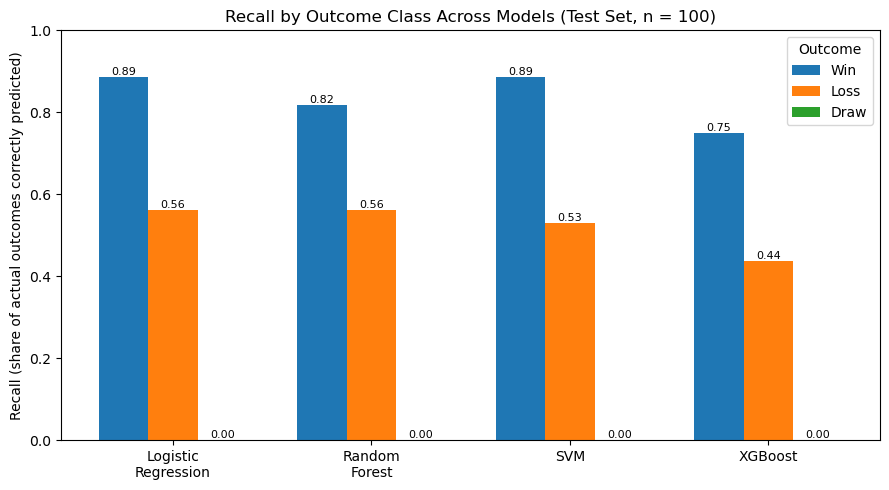

In [51]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import recall_score

# Recall per outcome class for each model, calculated from the actual predictions
models = ["Logistic\nRegression", "Random\nForest", "SVM", "XGBoost"]
all_preds = [pred_lr, pred_rf, pred_svm, pred_xgb]
classes = ["win", "loss", "draw"]
recall_table = pd.DataFrame(
    [recall_score(y_test, p, labels=classes, average=None, zero_division=0) for p in all_preds],
    index=["Logistic Regression", "Random Forest", "SVM", "XGBoost"], columns=classes).round(3)
print(recall_table)

x = np.arange(len(models))
width = 0.25
fig, ax = plt.subplots(figsize=(9, 5))
for i, cls in enumerate(classes):
    bars = ax.bar(x + (i - 1) * width, recall_table[cls], width, label=cls.capitalize())
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.set_ylabel("Recall (share of actual outcomes correctly predicted)")
ax.set_title("Recall by Outcome Class Across Models (Test Set, n = 100)")
ax.legend(title="Outcome")
plt.tight_layout()
plt.show()

**Confusion matrix for Random Forest**

Visualising Random Forest's confusion matrix to show exactly where draw predictions are being misclassified to, since the classification report shows draws are never correctly predicted.

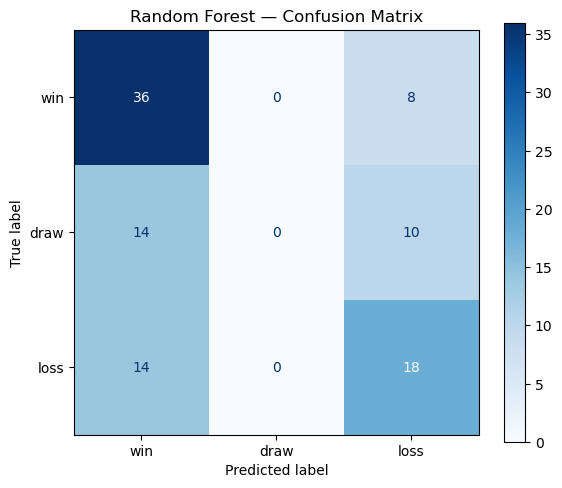

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay

# Plot confusion matrix for Random Forest, showing where each true class gets predicted
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_rf, labels=["win", "draw", "loss"], ax=ax, cmap="Blues")
ax.set_title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

**Summary of findings so far**

All four models reached similar overall test accuracy (47–57%), but **none of them correctly predicted a single draw** (draw precision, recall, and F1-score = 0.000 for every model). Logistic Regression and Random Forest never predicted a draw at all, while SVM and XGBoost predicted "draw" only once and twice respectively, each time for a match that was not a draw. The Random Forest confusion matrix shows where the actual draws went: all 24 were classified as either wins (14) or losses (10). In practice, the models reduced a three-outcome problem to a two-outcome one, so overall accuracy hides a complete failure on almost a quarter of the test matches.

### Feature Importance

Checking which pre-match features Random Forest and XGBoost relied on most when making predictions. These two models are less transparent than Logistic Regression, so feature importance helps explain their decisions, as set out in the ethical considerations (transparency and explainability).

                Random Forest  XGBoost
fifa_rank_diff          0.369    0.341
away_goals_avg          0.209    0.166
home_goals_avg          0.170    0.127
away_card_avg           0.143    0.120
home_card_avg           0.084    0.102
h2h_home_wins           0.018    0.000
home_advantage          0.006    0.144


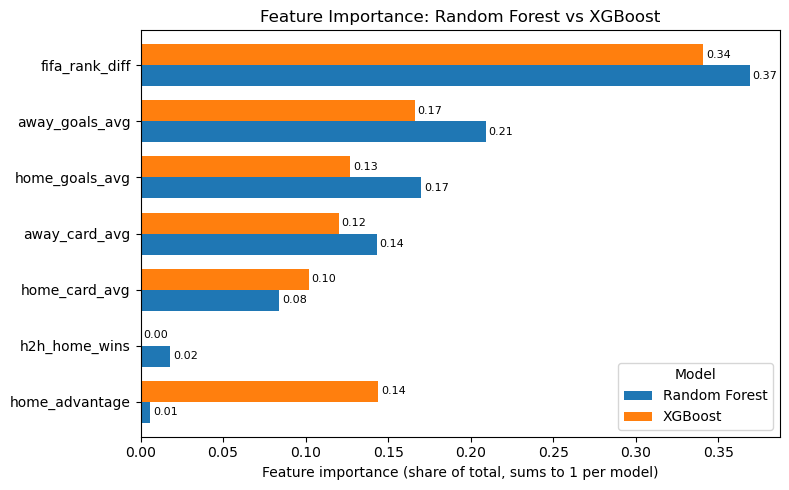

In [53]:
# Feature importance from the two tree-based models (how much each feature contributed to their predictions)
importance = pd.DataFrame({
    "Random Forest": rand_forest.feature_importances_,
    "XGBoost": xgb_model.feature_importances_
}, index=feature_cols).round(3).sort_values("Random Forest", ascending=True)
print(importance.sort_values("Random Forest", ascending=False))

ax = importance.plot(kind="barh", figsize=(8, 5), width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_xlabel("Feature importance (share of total, sums to 1 per model)")
ax.set_title("Feature Importance: Random Forest vs XGBoost")
ax.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

**Summary of feature importance**

Both tree-based models relied most heavily on FIFA ranking difference, followed by the goals-scored averages. Head-to-head record contributed almost nothing, since most team pairs had never met before in the dataset. The two models disagreed on home advantage (Random Forest gave it almost no weight, XGBoost a moderate weight), likely because only a few matches per tournament involve the host nation. The dominance of ranking difference helps explain the draw failure: a ranking gap signals which team is stronger, but none of the features directly captures how evenly matched two teams are, which is when draws are most likely.

## 10. Statistical Significance Testing

Testing whether the differences in model performance are statistically significant, per the methodology. A Friedman test compares all four models' cross-validation accuracy (Hypothesis Pair 1a), with a post-hoc Nemenyi test planned if significant. McNemar's test compares draw-prediction performance between every pair of models (Hypothesis Pair 2). Hypothesis Pair 1b is assessed by comparing the model rankings under overall accuracy and per-class metrics (Section 9).

### Collecting per-fold cross-validation scores

Re-running 5-fold cross-validation for each model's best hyperparameters to get individual fold scores, needed as input for the Friedman test.

In [54]:
from sklearn.model_selection import cross_val_score

In [55]:
# Get individual cross-validation fold accuracy scores for each model's best hyperparameters
scores_lr = cross_val_score(grid_lr.best_estimator_, X_train, y_train, cv=5, scoring="accuracy")
scores_rf = cross_val_score(grid_rf.best_estimator_, X_train, y_train, cv=5, scoring="accuracy")
scores_svm = cross_val_score(grid_svm.best_estimator_, X_train, y_train, cv=5, scoring="accuracy")
scores_xgb = cross_val_score(grid_xgb.best_estimator_, X_train, y_train_encoded, cv=5, scoring="accuracy")

print("Logistic Regression folds:", scores_lr.round(3))
print("Random Forest folds:", scores_rf.round(3))
print("SVM folds:", scores_svm.round(3))
print("XGBoost folds:", scores_xgb.round(3))

Logistic Regression folds: [0.475 0.562 0.475 0.612 0.462]
Random Forest folds: [0.525 0.588 0.512 0.575 0.488]
SVM folds: [0.475 0.575 0.475 0.625 0.475]
XGBoost folds: [0.5   0.612 0.525 0.588 0.462]


### Friedman Test (Hypothesis Pairs 1a/1b)

Testing H0: no statistically significant difference in performance among the four models, against H1: a significant difference exists. The Friedman test is non-parametric and compares the four models across the same 5 cross-validation folds.

In [56]:
from scipy.stats import friedmanchisquare

In [57]:
# Friedman test comparing all four models' cross-validation fold accuracy scores
stat, p_value = friedmanchisquare(scores_lr, scores_rf, scores_svm, scores_xgb)
print("Friedman statistic:", round(stat, 3))
print("p-value:", round(p_value, 3))

if p_value < 0.05:
    print("Result: statistically significant difference (reject H0)")
else:
    print("Result: no statistically significant difference (fail to reject H0)")

Friedman statistic: 3.383
p-value: 0.336
Result: no statistically significant difference (fail to reject H0)


### McNemar's Test (Hypothesis Pair 2)

Since the Friedman test found no significant difference in overall accuracy, the post-hoc Nemenyi test is not applicable. Testing H0: no significant difference in draw-prediction performance between models, against H1: a significant difference exists. McNemar's test is applied to **all six model pairs**, using whether each model classified each test match correctly as "draw" or "not draw".

In [58]:
from statsmodels.stats.contingency_tables import mcnemar

In [59]:
from itertools import combinations

# For each model, mark whether it got the draw/not-draw decision right on each test match
y_test_array = y_test.values
draw_correct = {name: ((np.array(preds) == "draw") == (y_test_array == "draw")).astype(int)
                for name, preds in [("Logistic Regression", pred_lr), ("Random Forest", pred_rf), ("SVM", pred_svm), ("XGBoost", pred_xgb)]}

# Run McNemar's test on every pair of models
for a, b in combinations(draw_correct, 2):
    ca, cb = draw_correct[a], draw_correct[b]
    table = [[np.sum((ca == 1) & (cb == 1)), np.sum((ca == 1) & (cb == 0))],
             [np.sum((ca == 0) & (cb == 1)), np.sum((ca == 0) & (cb == 0))]]
    result = mcnemar(table, exact=True)
    print(f"{a} vs {b}: table = {[[int(v) for v in row] for row in table]}, p-value = {round(result.pvalue, 3)}")

Logistic Regression vs Random Forest: table = [[76, 0], [0, 24]], p-value = 1.0
Logistic Regression vs SVM: table = [[75, 1], [0, 24]], p-value = 1.0
Logistic Regression vs XGBoost: table = [[74, 2], [0, 24]], p-value = 0.5
Random Forest vs SVM: table = [[75, 1], [0, 24]], p-value = 1.0
Random Forest vs XGBoost: table = [[74, 2], [0, 24]], p-value = 0.5
SVM vs XGBoost: table = [[73, 2], [1, 24]], p-value = 1.0


**Summary of statistical testing**

The Friedman test found no statistically significant difference in overall accuracy among the four models (χ² = 3.383, p = 0.336), so H0 is not rejected for Hypothesis Pair 1a. McNemar's test found no significant difference in draw-prediction performance for any of the six model pairs (all p ≥ 0.5), so H0 is not rejected for Hypothesis Pair 2. The contingency tables show why: no model correctly identified any of the 24 actual draws, and the only differences between models were one or two incorrect "draw" predictions by SVM and XGBoost. This also means H1's expectation that the ensemble models (Random Forest, XGBoost) would outperform Logistic Regression on draws was not supported. The practically meaningful finding is not which model performs best, but that all four models failed completely at draw prediction, regardless of algorithm or overall accuracy.

## 11. Robustness Check: Chronological Split

To check whether the random stratified split affected the conclusions, the four models are retrained on the earlier tournaments (1994–2014) and tested on the two most recent tournaments (2018–2022), using the same best hyperparameters found in Section 8. This mimics real forecasting, where a model only learns from the past and predicts the future.

In [60]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

In [61]:
# Chronological split: train on 1994-2014, test on 2018-2022
train_mask = matches_filtered["Year"] <= 2014
X_train_chr, X_test_chr = matches_filtered[train_mask][feature_cols], matches_filtered[~train_mask][feature_cols]
y_train_chr, y_test_chr = matches_filtered[train_mask]["outcome"], matches_filtered[~train_mask]["outcome"]
print("Train:", X_train_chr.shape, " Test:", X_test_chr.shape)
print("Test class counts:", y_test_chr.value_counts().to_dict())

Train: (372, 7)  Test: (128, 7)
Test class counts: {'win': 55, 'loss': 45, 'draw': 28}


In [62]:
# Retrain each model (same best hyperparameters) on the earlier tournaments and test on the recent ones
chr_results = []
for name, grid in [("Logistic Regression", grid_lr), ("Random Forest", grid_rf), ("SVM", grid_svm), ("XGBoost", grid_xgb)]:
    model = clone(grid.best_estimator_)
    if name == "XGBoost":
        model.fit(X_train_chr, label_encoder.transform(y_train_chr))
        preds = label_encoder.inverse_transform(model.predict(X_test_chr))
    else:
        model.fit(X_train_chr, y_train_chr)
        preds = model.predict(X_test_chr)
    chr_results.append({"Model": name,
                        "Accuracy": round(accuracy_score(y_test_chr, preds), 3),
                        "Draw recall": round(recall_score(y_test_chr, preds, labels=["draw"], average=None, zero_division=0)[0], 3),
                        "Macro F1": round(f1_score(y_test_chr, preds, average="macro", zero_division=0), 3),
                        "Draws predicted": int((preds == "draw").sum())})
pd.DataFrame(chr_results)

,Model,Accuracy,Draw recall,Macro F1,Draws predicted
0,Logistic Regression,0.523,0.0,0.390,2
1,Random Forest,0.539,0.0,0.401,1
2,SVM,0.516,0.0,0.383,1
3,XGBoost,0.523,0.0,0.386,1


**Summary of robustness check**

Under a chronological split (train 1994–2014, n = 372; test 2018–2022, n = 128), all four models reached similar accuracy (51.6%–53.9%) and **none correctly predicted any of the 28 draws** in the 2018 and 2022 tournaments (draw recall = 0.0 for every model). The few "draw" predictions made (one or two per model) were all incorrect. This matches the random stratified split results, showing that the draw-prediction failure is not caused by the choice of splitting method.